In [78]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [3]:
data = pd.read_pickle('data_mod.pkl')
data.head()

,k1,k2,k3,k4,k5,k6,k7,k9,k10,k11,k12,k13,k14,k15,k16,k17,k18,k19,k20
0,0.403809,0.503518,0.548820,0.328302,0.330954,0.475458,0.833823,0.529053,0.330879,0.414133,0.451272,0.309298,0.359411,0.340312,0.459953,1.000000,0.554562,0.497247,0.479035
1,0.591695,0.653597,0.632007,0.763404,0.169329,0.543158,0.421875,0.903975,0.333300,0.515462,0.471764,0.330484,0.592674,0.566433,0.490934,1.000000,0.678800,0.510526,0.458055
2,0.300968,0.462057,0.341906,0.000000,0.379270,0.893999,1.000000,0.511229,0.284299,0.173041,0.502503,0.083725,0.220906,0.402367,1.000000,0.558105,0.000000,0.371303,0.399927
3,1.000000,1.000000,1.000000,0.902599,0.126387,0.311175,0.433346,0.999822,0.607228,0.489965,0.564472,1.000000,1.000000,0.942774,0.418881,0.546973,0.854628,1.000000,1.000000
4,0.555295,0.464936,0.620328,0.709942,0.235475,1.000000,0.927524,0.752390,0.374004,0.243528,0.407338,0.231825,0.403838,0.317202,0.420597,0.496557,0.516877,0.414231,0.426759


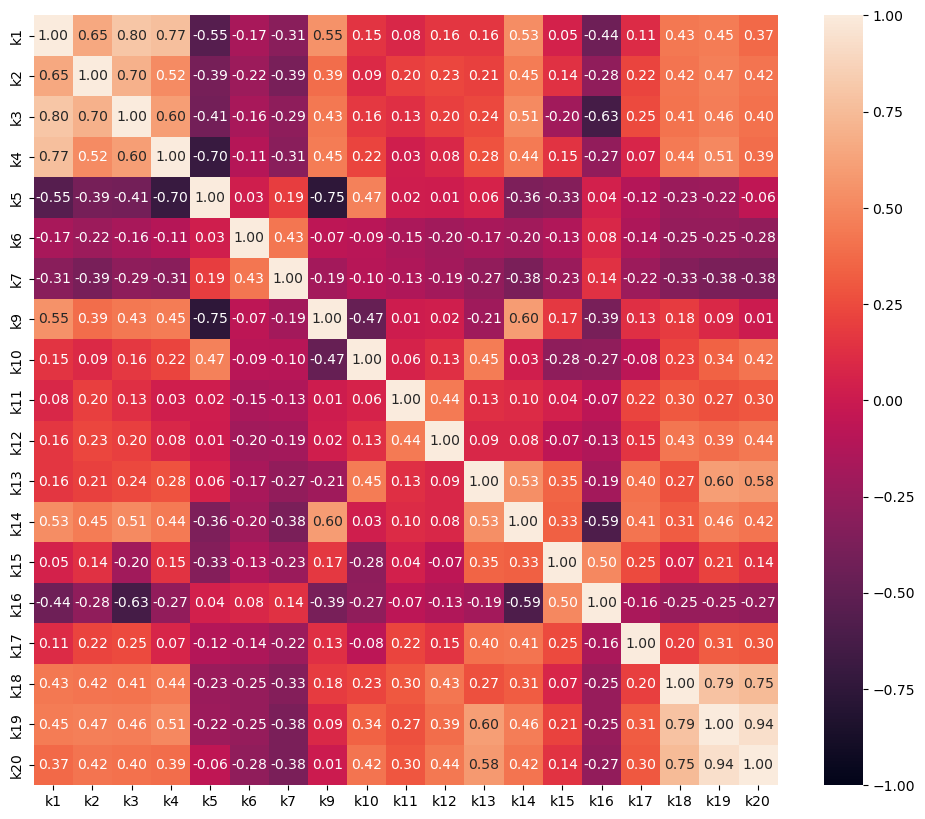

In [11]:
corr_matrix = data.corr(method = 'spearman')
plt.figure(figsize = (12, 10))
sns.heatmap(corr_matrix, annot = True, fmt = ".2f", vmin = -1, vmax = 1)
plt.show()

In [34]:
upper_matrix = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k = 1).astype(bool))
pairs = upper_matrix.stack().reset_index()
pairs.columns = ['comp_1', 'comp_2', 'correlation']

high_corr = pairs[pairs['correlation'].abs() >= 0.7].copy()
high_corr['abs_corr'] = high_corr['correlation'].abs()

variances = data.var()
high_corr['variance_1'] = high_corr['comp_1'].map(variances)
high_corr['variance_2'] = high_corr['comp_2'].map(variances)

mean_corr = (corr_matrix.abs().sum() - 1) / (corr_matrix.shape[0] - 1)
high_corr['mean_corr_1'] = high_corr['comp_1'].map(mean_corr)
high_corr['mean_corr_2'] = high_corr['comp_2'].map(mean_corr)

high_corr = high_corr.sort_values('abs_corr', ascending = False)

display(high_corr)

,comp_1,comp_2,correlation,abs_corr,variance_1,variance_2,mean_corr_1,mean_corr_2
170,k19,k20,0.936348,0.936348,0.048266,0.045533,0.410686,0.381905
1,k1,k3,0.799381,0.799381,0.035192,0.036225,0.373681,0.388156
168,k18,k19,0.786707,0.786707,0.048789,0.048266,0.349179,0.410686
2,k1,k4,0.768712,0.768712,0.035192,0.059154,0.373681,0.352035
68,k5,k9,-0.751843,0.751843,0.069029,0.039173,0.275118,0.284287
169,k18,k20,0.749399,0.749399,0.048789,0.045533,0.349179,0.381905
18,k2,k3,0.701324,0.701324,0.026848,0.036225,0.355249,0.388156


In [39]:
data = data.drop(['k19', 'k3', 'k1', 'k9', 'k20'], axis = 1)
data.head()

,k2,k4,k5,k6,k7,k10,k11,k12,k13,k14,k15,k16,k17,k18
0,0.503518,0.328302,0.330954,0.475458,0.833823,0.330879,0.414133,0.451272,0.309298,0.359411,0.340312,0.459953,1.000000,0.554562
1,0.653597,0.763404,0.169329,0.543158,0.421875,0.333300,0.515462,0.471764,0.330484,0.592674,0.566433,0.490934,1.000000,0.678800
2,0.462057,0.000000,0.379270,0.893999,1.000000,0.284299,0.173041,0.502503,0.083725,0.220906,0.402367,1.000000,0.558105,0.000000
3,1.000000,0.902599,0.126387,0.311175,0.433346,0.607228,0.489965,0.564472,1.000000,1.000000,0.942774,0.418881,0.546973,0.854628
4,0.464936,0.709942,0.235475,1.000000,0.927524,0.374004,0.243528,0.407338,0.231825,0.403838,0.317202,0.420597,0.496557,0.516877


In [40]:
data.to_pickle('downsc_data.pkl')

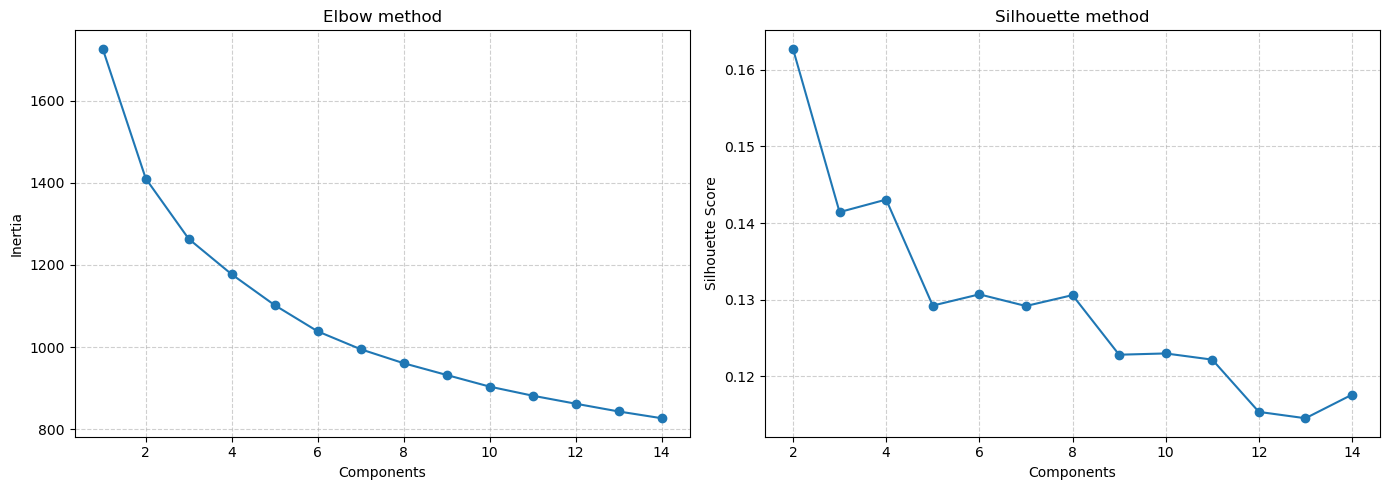

In [75]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

inertias = []
silhouettes = []

for k in range(1, 15):
    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 10) #если колличество инициализаций auto то пик приходится на 6
    labels = kmeans.fit_predict(data)
    
    inertias.append(kmeans.inertia_)
    if k > 1:
        silhouettes.append(silhouette_score(data, labels))

    
ax1.plot(range(1,15), inertias, marker = 'o')
ax1.set_title('Elbow method')
ax1.set_xlabel('Components')
ax1.set_ylabel('Inertia')
ax1.grid(True, linestyle = '--', alpha = 0.6)

ax2.plot(range(2,15), silhouettes, marker = 'o')
ax2.set_title('Silhouette method')
ax2.set_xlabel('Components')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True, linestyle = '--', alpha = 0.6)

plt.tight_layout()
plt.show()

In [72]:
pca = PCA(n_components = 3)
axes = pca.fit_transform(data)

In [82]:
kmeans_4 = KMeans(n_clusters = 4, random_state = 42, n_init = 10)
labels_4 = kmeans_4.fit_predict(axes)

kmeans_6 = KMeans(n_clusters = 6, random_state = 42, n_init = 10)
labels_6 = kmeans_6.fit_predict(axes)

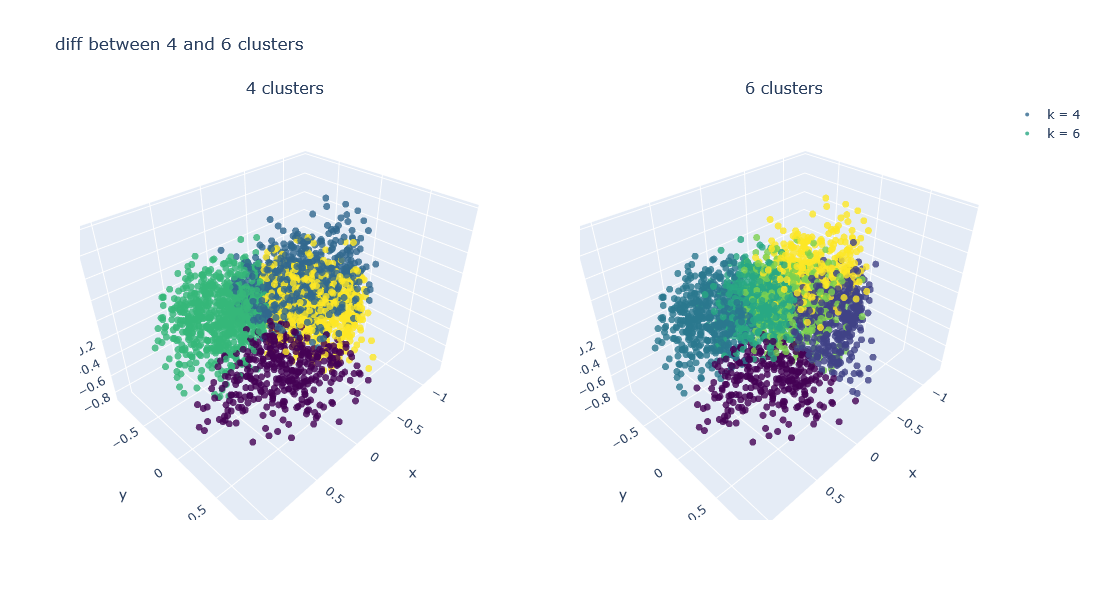

In [86]:
fig = make_subplots(rows = 1, cols = 2, specs = [[{'type': 'scene'}, {'type': 'scene'}]], subplot_titles = ('4 clusters', '6 clusters'))

fig.add_trace(go.Scatter3d(x = axes[:, 0], y = axes[:, 1], z = axes[:, 2], mode = 'markers',
                           marker = dict(size = 4, color = labels_4, colorscale = 'Viridis', opacity = 0.8), name = 'k = 4'), row = 1, col = 1)

fig.add_trace(go.Scatter3d(x = axes[:, 0], y = axes[:, 1], z = axes[:, 2], mode = 'markers',
                           marker = dict(size = 4, color = labels_6, colorscale = 'Viridis', opacity = 0.8), name = 'k = 6'), row = 1, col = 2)

fig.update_layout(height = 600, width = 1200, title_text = 'diff between 4 and 6 clusters')
fig.show()